In [1]:
import json
from pathlib import Path

import clip
import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import sys

sys.path.insert(0, '/notebooks/experiment/codes')

RUN_DIR   = Path('/notebooks/experiment/4M_checkpoints/vib_hd256_tok1_initbase_lslr0.2_lsmax116_vib0.0001_binit3e-06_lvbias-6.0_vwarm0.5_klvw0.1_lvclip-3.0')
RUN_LABEL = 'VIB klvw=0.1, lvclip=-3.0, warm=0.5, β=1e-4'

BASE_RUN  = Path('/notebooks/experiment/4M_checkpoints/base_hd256_tok1_lslr0.2_lsmax116')
EVAL_DIR  = Path('/notebooks/experiment/eval_data/fashion_iq')

PREV_RUN  = Path('/notebooks/experiment/4M_checkpoints/vib_hd256_tok1_initbase_lslr0.2_lsmax116_vib0.0001_binit3e-06_lvbias-6.0_vwarm0.5')
PREV_LABEL = 'VIB klvw=1.0 (run 2 — failed)'

device = 'cuda'

plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

print(f'Run: {RUN_LABEL}')
print(f'Path: {RUN_DIR}')
print(f'Exists: {RUN_DIR.exists()}')

Run: VIB klvw=0.1, lvclip=-3.0, warm=0.5, β=1e-4
Path: /notebooks/experiment/4M_checkpoints/vib_hd256_tok1_initbase_lslr0.2_lsmax116_vib0.0001_binit3e-06_lvbias-6.0_vwarm0.5_klvw0.1_lvclip-3.0
Exists: True


In [2]:
ckpt_path = RUN_DIR / 'epoch_00' / 'checkpoint.pt'
ckpt = torch.load(ckpt_path, map_location='cpu')
cfg_dict = ckpt.get('config', {})

print(f'='*70)
print(f'CONFIG  ({RUN_LABEL})')
print(f'='*70)
print(f'Saved at epoch: {ckpt.get("epoch")}')
print(f'logit_scale at save: {ckpt.get("logit_scale", 0):.4f} (exp={torch.tensor(ckpt.get("logit_scale", 0)).exp().item():.2f})')
print(f'')

keys_to_show = [
    'mapper_type', 'hidden_dim', 'num_tokens', 'dropout',
    'lr', 'weight_decay', 'grad_clip',
    'ls_lr_scale', 'ls_max',
    'vib_beta', 'vib_beta_initial', 'vib_beta_warmup',
    'vib_logvar_bias', 'vib_kl_mu_weight', 'vib_kl_var_weight',
    'vib_logvar_clip_max',
    'init_from', 'batch_size', 'epochs',
]
for k in keys_to_show:
    if k in cfg_dict:
        print(f'  {k:25s}: {cfg_dict[k]}')

CONFIG  (VIB klvw=0.1, lvclip=-3.0, warm=0.5, β=1e-4)
Saved at epoch: 0
logit_scale at save: 4.7018 (exp=110.15)

  mapper_type              : vib
  hidden_dim               : 256
  num_tokens               : 1
  dropout                  : 0.1
  lr                       : 0.0001
  weight_decay             : 0.1
  grad_clip                : 1.0
  ls_lr_scale              : 0.2
  ls_max                   : 116.0
  vib_beta                 : 0.0001
  vib_beta_initial         : 3e-06
  vib_beta_warmup          : 0.5
  vib_logvar_bias          : -6.0
  vib_kl_mu_weight         : 1.0
  vib_kl_var_weight        : 0.1
  vib_logvar_clip_max      : -3.0
  init_from                : /notebooks/experiment/4M_checkpoints/base_hd256_tok1_lslr0.2_lsmax116/epoch_01/checkpoint.pt
  batch_size               : 1024
  epochs                   : 5


In [3]:
src_eval = json.load(open(BASE_RUN / 'epoch_01' / 'fashion_eval.json'))
print('BaseMLP slowLS source (epoch_01) — sanity = 25.82%')
print('-'*70)
for cat in ['dress','shirt','toptee','avg']:
    v = src_eval.get(cat, {})
    print(f'  {cat:8s}  R@1={v.get("1",0)*100:5.1f}%  R@5={v.get("5",0)*100:5.1f}%  R@10={v.get("10",0)*100:5.1f}%  R@50={v.get("50",0)*100:5.1f}%')

SOURCE_R10_AVG    = src_eval['avg']['10'] * 100
SOURCE_R10_DRESS  = src_eval['dress']['10'] * 100
SOURCE_R10_SHIRT  = src_eval['shirt']['10'] * 100
SOURCE_R10_TOPTEE = src_eval['toptee']['10'] * 100
print(f'\n→ Source avg R@10 stored: {SOURCE_R10_AVG:.1f}%')

BaseMLP slowLS source (epoch_01) — sanity = 25.82%
----------------------------------------------------------------------
  dress     R@1=  4.9%  R@5= 14.6%  R@10= 20.3%  R@50= 42.0%
  shirt     R@1=  7.7%  R@5= 20.3%  R@10= 28.0%  R@50= 45.8%
  toptee    R@1=  8.3%  R@5= 21.3%  R@10= 29.2%  R@50= 48.8%
  avg       R@1=  6.9%  R@5= 18.7%  R@10= 25.8%  R@50= 45.6%

→ Source avg R@10 stored: 25.8%


Loaded 100 rows from training_stats.tsv
Columns: ['epoch', 'step', 'global_step', 'loss', 'l_t2i', 'l_i2t', 'lr', 'ls', 'lambda_m', 'kl', 'kl_mu', 'kl_var', 'kl_mu_weighted', 'kl_var_weighted', 'beta', 'mu_norm', 'logvar_mean', 'std_mean']

Last 5 rows:
 global_step     loss    l_t2i    l_i2t       kl   kl_mu    kl_var     beta
        8312 0.013142 0.001397 0.001539 136.4285 28.5414 1078.8712 0.000086
        8412 0.013120 0.001382 0.001339 135.8506 29.0162 1068.3438 0.000087
        8512 0.013425 0.001500 0.001609 135.5796 28.9157 1066.6387 0.000088
        8612 0.015730 0.002962 0.004755 134.0767 29.2066 1048.7007 0.000089
        8712 0.012902 0.000747 0.001062 133.9943 29.3693 1046.2494 0.000090


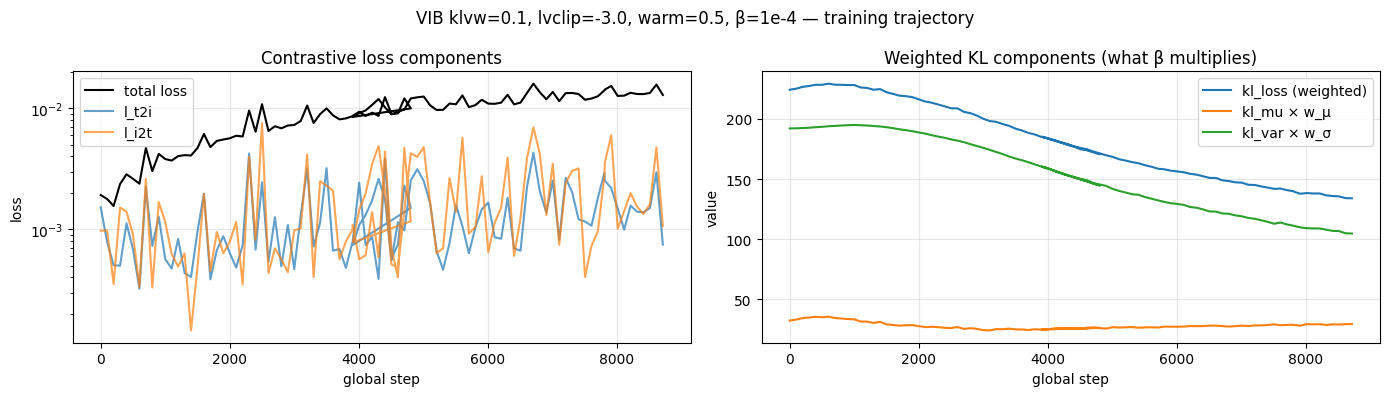

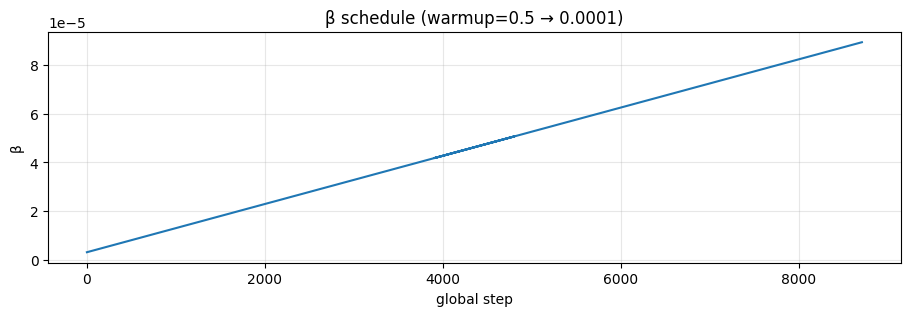

In [4]:
tsv_path = RUN_DIR / 'training_stats.tsv'
df = pd.read_csv(tsv_path, sep='\t')
print(f'Loaded {len(df)} rows from training_stats.tsv')
print(f'Columns: {list(df.columns)}')
print(f'\nLast 5 rows:')
print(df.tail(5)[['global_step','loss','l_t2i','l_i2t','kl','kl_mu','kl_var','beta']].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax = axes[0]
ax.plot(df['global_step'], df['loss'], label='total loss', color='black')
ax.plot(df['global_step'], df['l_t2i'], label='l_t2i', alpha=0.7)
ax.plot(df['global_step'], df['l_i2t'], label='l_i2t', alpha=0.7)
ax.set_xlabel('global step')
ax.set_ylabel('loss')
ax.set_title('Contrastive loss components')
ax.legend()
ax.set_yscale('log')

ax = axes[1]
ax.plot(df['global_step'], df['kl'], label='kl_loss (weighted)', color='C0')
if 'kl_mu_weighted' in df.columns:
    ax.plot(df['global_step'], df['kl_mu_weighted'], label='kl_mu × w_μ', color='C1')
    ax.plot(df['global_step'], df['kl_var_weighted'], label='kl_var × w_σ', color='C2')
ax.set_xlabel('global step')
ax.set_ylabel('value')
ax.set_title('Weighted KL components (what β multiplies)')
ax.legend()

plt.suptitle(f'{RUN_LABEL} — training trajectory')
plt.tight_layout()
plt.show()

# Plot β schedule
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(df['global_step'], df['beta'])
ax.set_xlabel('global step')
ax.set_ylabel('β')
ax.set_title(f'β schedule (warmup={cfg_dict.get("vib_beta_warmup")} → {cfg_dict.get("vib_beta")})')
plt.show()

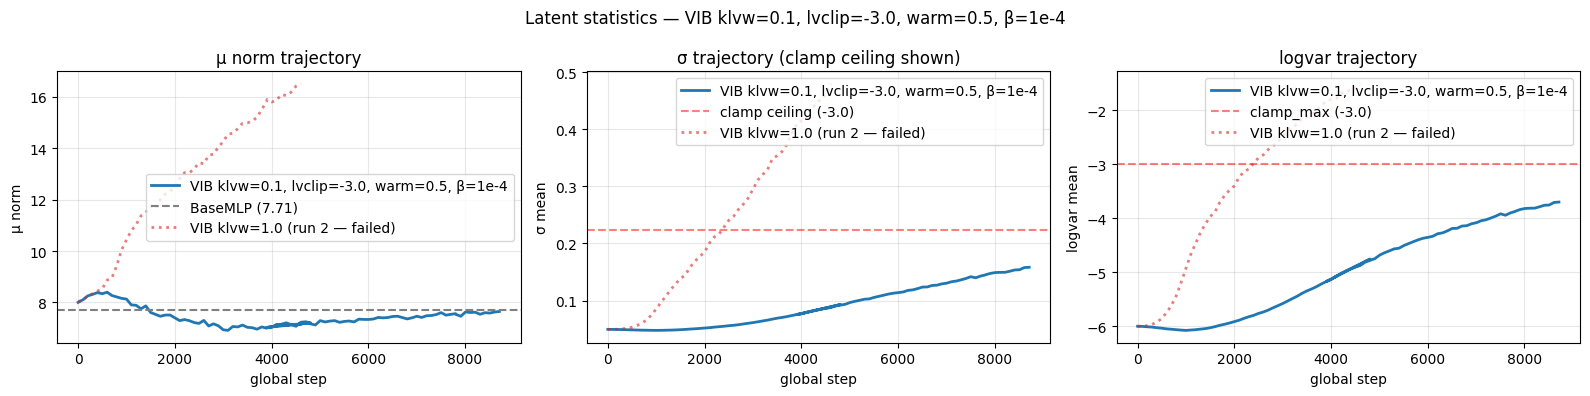

Latest TSV row (step 8712):
  μ_norm     = 7.648  (BaseMLP: 7.71)
  σ mean     = 0.1584  (clamp: -3.0)
  logvar     = -3.699


In [5]:
# Plot μ_norm, σ, logvar over time. This is the core latent-health diagnostic.
# Compare against the previous failed run if available.

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ax = axes[0]
ax.plot(df['global_step'], df['mu_norm'], label=RUN_LABEL, color='C0', linewidth=2)
ax.axhline(y=7.71, linestyle='--', color='gray', label='BaseMLP (7.71)')

prev_tsv = PREV_RUN / 'training_stats.tsv'
if prev_tsv.exists():
    df_prev = pd.read_csv(prev_tsv, sep='\t')
    ax.plot(df_prev['global_step'], df_prev['mu_norm'], label=PREV_LABEL,
            color='C3', linewidth=2, alpha=0.6, linestyle=':')

ax.set_xlabel('global step')
ax.set_ylabel('μ norm')
ax.set_title('μ norm trajectory')
ax.legend()

ax = axes[1]
ax.plot(df['global_step'], df['std_mean'], label=RUN_LABEL, color='C0', linewidth=2)
ax.axhline(y=0.2231, linestyle='--', color='red', alpha=0.5,
           label=f'clamp ceiling ({cfg_dict.get("vib_logvar_clip_max")})')
if prev_tsv.exists():
    ax.plot(df_prev['global_step'], df_prev['std_mean'], label=PREV_LABEL,
            color='C3', linewidth=2, alpha=0.6, linestyle=':')
ax.set_xlabel('global step')
ax.set_ylabel('σ mean')
ax.set_title('σ trajectory (clamp ceiling shown)')
ax.legend()

ax = axes[2]
ax.plot(df['global_step'], df['logvar_mean'], label=RUN_LABEL, color='C0', linewidth=2)
ax.axhline(y=cfg_dict.get('vib_logvar_clip_max', 2.0), linestyle='--', color='red', alpha=0.5,
           label=f'clamp_max ({cfg_dict.get("vib_logvar_clip_max")})')
if prev_tsv.exists():
    ax.plot(df_prev['global_step'], df_prev['logvar_mean'], label=PREV_LABEL,
            color='C3', linewidth=2, alpha=0.6, linestyle=':')
ax.set_xlabel('global step')
ax.set_ylabel('logvar mean')
ax.set_title('logvar trajectory')
ax.legend()

plt.suptitle(f'Latent statistics — {RUN_LABEL}')
plt.tight_layout()
plt.show()

last = df.iloc[-1]
print(f'Latest TSV row (step {last["global_step"]:.0f}):')
print(f'  μ_norm     = {last["mu_norm"]:.3f}  (BaseMLP: 7.71)')
print(f'  σ mean     = {last["std_mean"]:.4f}  (clamp: {cfg_dict.get("vib_logvar_clip_max")})')
print(f'  logvar     = {last["logvar_mean"]:.3f}')

In [6]:
step_log = RUN_DIR / 'step_evals' / 'eval_log.txt'
print(open(step_log).read())

step_jsons = sorted((RUN_DIR / 'step_evals').glob('step_*.json'))
recall_traj = []
for p in step_jsons:
    payload = json.load(open(p))
    fe = payload.get('fashion_eval', {})
    recall_traj.append({
        'step': payload['step'],
        'global_step': payload.get('global_step', payload['step']),
        'epoch': payload['epoch'],
        'dress':  fe.get('dress',  {}).get('10', 0) * 100,
        'shirt':  fe.get('shirt',  {}).get('10', 0) * 100,
        'toptee': fe.get('toptee', {}).get('10', 0) * 100,
        'avg':    fe.get('avg',    {}).get('10', 0) * 100,
    })
df_recall = pd.DataFrame(recall_traj)
df_recall['label'] = df_recall.apply(lambda r: f'ep{int(r.epoch):02d}_{int(r.step):05d}', axis=1)
print('\nRecall trajectory:')
print(df_recall.to_string(index=False))

[Epoch 00 | Step 00500 | Global 000500]  dress R@10=20.2%  shirt R@10=26.8%  toptee R@10=28.3%  |  avg R@10=25.1%
[Epoch 00 | Step 01000 | Global 001000]  dress R@10=19.5%  shirt R@10=28.1%  toptee R@10=28.3%  |  avg R@10=25.3%
[Epoch 00 | Step 01500 | Global 001500]  dress R@10=20.0%  shirt R@10=27.5%  toptee R@10=28.9%  |  avg R@10=25.5%
[Epoch 00 | Step 02000 | Global 002000]  dress R@10=20.7%  shirt R@10=27.2%  toptee R@10=28.6%  |  avg R@10=25.5%
[Epoch 00 | Step 02500 | Global 002500]  dress R@10=20.8%  shirt R@10=26.7%  toptee R@10=28.7%  |  avg R@10=25.4%
[Epoch 00 | Step 03000 | Global 003000]  dress R@10=20.5%  shirt R@10=27.0%  toptee R@10=28.0%  |  avg R@10=25.2%
[Epoch 00 | Step 03500 | Global 003500]  dress R@10=20.5%  shirt R@10=27.3%  toptee R@10=28.5%  |  avg R@10=25.4%
[Epoch 01 | Step 00500 | Global 004406]  dress R@10=20.1%  shirt R@10=26.3%  toptee R@10=27.4%  |  avg R@10=24.6%
[Epoch 01 | Step 00500 | Global 004406]  dress R@10=20.2%  shirt R@10=27.4%  toptee R@10

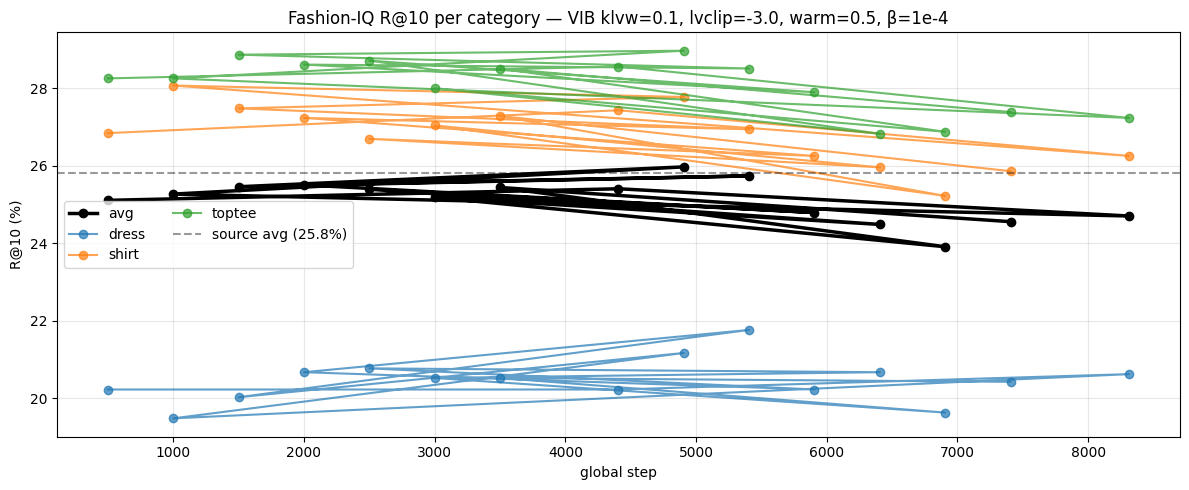

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_recall['global_step'], df_recall['avg'],    'o-', label='avg',    color='black', linewidth=2.5)
ax.plot(df_recall['global_step'], df_recall['dress'],  'o-', label='dress',  alpha=0.7)
ax.plot(df_recall['global_step'], df_recall['shirt'],  'o-', label='shirt',  alpha=0.7)
ax.plot(df_recall['global_step'], df_recall['toptee'], 'o-', label='toptee', alpha=0.7)

ax.axhline(y=SOURCE_R10_AVG,    linestyle='--', color='black', alpha=0.4, label=f'source avg ({SOURCE_R10_AVG:.1f}%)')

ax.set_xlabel('global step')
ax.set_ylabel('R@10 (%)')
ax.set_title(f'Fashion-IQ R@10 per category — {RUN_LABEL}')
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

In [8]:
# === 08_step_stickiness ===
# Run stickiness analysis on every saved step checkpoint.
# OPTIMIZED:
#   - Pre-encode ref+gt images ONCE (frozen CLIP image encoder)
#   - Pre-tokenize captions ONCE
#   - Per checkpoint, only re-run the mapper + text transformer pipeline
#   - Save partial CSV after each checkpoint (resilient to notebook crashes)

import time
from model.model import Pic2Word
from config.config import load_from_yaml

# ----------------------------------------------------------
# 1. Setup: load CLIP preprocess + per-category data
# ----------------------------------------------------------
_, preprocess = clip.load('ViT-L/14', device='cpu')
categories = ['dress', 'shirt', 'toptee']
img_root = EVAL_DIR / 'images' / 'images'

# Output CSV path (loaded incrementally so we can resume)
csv_path = RUN_DIR / 'stickiness_per_step.csv'

# ----------------------------------------------------------
# 2. Pre-encode all per-category image data (ONCE, ~30 sec)
#    These are frozen across all checkpoints, so cache aggressively.
# ----------------------------------------------------------
print('Pre-encoding per-category image data (frozen)...')
t0 = time.time()

# We need *some* model just to access the frozen CLIP backbone.
# Using BaseMLP since it's the smallest and we only need image encoding.
src_ckpt = torch.load(BASE_RUN / 'epoch_01' / 'checkpoint.pt', map_location='cpu')
src_cfg  = load_from_yaml('/notebooks/experiment/codes/config/config.yaml',
    mapper_type='base', hidden_dim=256, num_tokens=1, device=device)
shared_clip_model = Pic2Word(src_cfg).to(device)
shared_clip_model.eval()

BATCH_SIZE = 64
fiq_data = {}

for cat in categories:
    ann      = json.load(open(EVAL_DIR / 'captions' / f'cap.{cat}.val.json'))
    gallery  = torch.load(EVAL_DIR / f'gallery_cache_{cat}_ViT-L-14.pt', map_location=device)
    if isinstance(gallery, dict):
        gallery = gallery['embeddings']
    gallery  = F.normalize(gallery.to(device), dim=-1)
    id_list  = json.load(open(EVAL_DIR / 'image_splits' / f'split.{cat}.val.json'))
    id_to_idx = {iid: i for i, iid in enumerate(id_list)}
    
    # Filter annotations: ref image must exist on disk
    valid_ann = []
    for a in ann:
        ref_path = img_root / f'{a["candidate"]}.png'
        if not ref_path.exists():
            ref_path = img_root / f'{a["candidate"]}.jpg'
        if not ref_path.exists():
            continue
        valid_ann.append(a)
    
    # Pre-load preprocessed ref images (we'll need actual image tensors for encode_query)
    ref_imgs_pre = []
    ref_paths    = []
    for a in valid_ann:
        ref_path = img_root / f'{a["candidate"]}.png'
        if not ref_path.exists():
            ref_path = img_root / f'{a["candidate"]}.jpg'
        ref_imgs_pre.append(preprocess(Image.open(ref_path).convert('RGB')))
        ref_paths.append(ref_path)
    ref_imgs_pre = torch.stack(ref_imgs_pre)  # (N_q, 3, 224, 224) on CPU
    
    # Pre-encode all GT images (normalized — for sim(p, v_gt))
    gt_embs = []
    with torch.no_grad():
        # Collect unique GT image tensors first
        unique_gt_ids = list(set(a['target'] for a in valid_ann))
        gt_tensors = []
        existing_gt_ids = []
        for gt_id in unique_gt_ids:
            gt_path = img_root / f'{gt_id}.png'
            if not gt_path.exists():
                gt_path = img_root / f'{gt_id}.jpg'
            if gt_path.exists():
                gt_tensors.append(preprocess(Image.open(gt_path).convert('RGB')))
                existing_gt_ids.append(gt_id)
        if gt_tensors:
            gt_tensors = torch.stack(gt_tensors)
            for i in range(0, len(gt_tensors), BATCH_SIZE):
                batch = gt_tensors[i:i+BATCH_SIZE].to(device)
                emb   = shared_clip_model.clip.encode_image(batch)  # normalized
                gt_embs.append(emb)
            gt_embs = torch.cat(gt_embs, dim=0)
            gt_id_to_emb_idx = {iid: i for i, iid in enumerate(existing_gt_ids)}
        else:
            gt_embs = None
            gt_id_to_emb_idx = {}
    
    # Pre-encode all REF images (normalized — for sim(p, v_ref))
    ref_embs_norm = []
    with torch.no_grad():
        for i in range(0, len(ref_imgs_pre), BATCH_SIZE):
            batch = ref_imgs_pre[i:i+BATCH_SIZE].to(device)
            emb   = shared_clip_model.clip.encode_image(batch)  # normalized
            ref_embs_norm.append(emb)
    ref_embs_norm = torch.cat(ref_embs_norm, dim=0)  # (N_q, D)
    
    # Pre-tokenize all captions
    captions = [a['captions'][0] + ' and ' + a['captions'][1] for a in valid_ann]
    txt_tokens = clip.tokenize(captions, truncate=True).to(device)  # (N_q, 77)
    
    # GT embedding lookup per query
    gt_emb_idx = []
    has_gt     = []
    for a in valid_ann:
        if a['target'] in gt_id_to_emb_idx:
            gt_emb_idx.append(gt_id_to_emb_idx[a['target']])
            has_gt.append(True)
        else:
            gt_emb_idx.append(0)
            has_gt.append(False)
    gt_emb_idx = torch.tensor(gt_emb_idx, dtype=torch.long, device=device)
    has_gt     = torch.tensor(has_gt,     dtype=torch.bool, device=device)
    
    fiq_data[cat] = {
        'annotations'   : valid_ann,
        'gallery'       : gallery,
        'id_to_idx'     : id_to_idx,
        'ref_imgs_pre'  : ref_imgs_pre,    # (N_q, 3, 224, 224) — CPU; move per-batch
        'ref_embs_norm' : ref_embs_norm,   # (N_q, D) — for sim(p, v_ref)
        'gt_embs'       : gt_embs,         # (N_unique_gt, D) — for sim(p, v_gt)
        'gt_emb_idx'    : gt_emb_idx,      # (N_q,)
        'has_gt'        : has_gt,          # (N_q,)
        'txt_tokens'    : txt_tokens,      # (N_q, 77)
    }
    print(f'  {cat:8s}: {len(valid_ann)} queries, {gallery.shape[0]} gallery, '
          f'{len(unique_gt_ids)} unique GT imgs')

del shared_clip_model
torch.cuda.empty_cache()
print(f'\nPre-encoding done in {time.time()-t0:.1f}s\n')


# ----------------------------------------------------------
# 3. Per-checkpoint analysis using cached embeddings.
# ----------------------------------------------------------
QUERY_BATCH = 32  # batch for encode_query — adjust based on GPU memory

def stickiness_for_model_fast(model):
    """
    Per-checkpoint stickiness. Reuses cached preprocessed images, cached
    ref_embs_norm, cached gt_embs, cached tokenized captions. The only
    per-checkpoint compute is encode_query (which still re-runs the
    image encoder on ref images — TODO: avoid this with a model-side helper).
    """
    model.eval()
    overall = {'sim_ref': [], 'sim_gt': [], 'r10_ref': [], 'r10_gt': [],
               'rank_ref': [], 'rank_gt': []}
    
    for cat in categories:
        d           = fiq_data[cat]
        gallery     = d['gallery']
        ref_imgs    = d['ref_imgs_pre']      # CPU, (N_q, 3, 224, 224)
        ref_embs    = d['ref_embs_norm']     # GPU, (N_q, D)
        gt_embs     = d['gt_embs']
        gt_emb_idx  = d['gt_emb_idx']
        has_gt      = d['has_gt']
        txt_tokens  = d['txt_tokens']
        ann         = d['annotations']
        id_to_idx   = d['id_to_idx']
        
        N_q = len(ann)
        
        # Compute query embeddings p in batches
        all_p = []
        with torch.no_grad():
            for i in range(0, N_q, QUERY_BATCH):
                ref_batch = ref_imgs[i:i+QUERY_BATCH].to(device)
                tok_batch = txt_tokens[i:i+QUERY_BATCH]
                p = model.encode_query(ref_batch, tok_batch)  # (B, D), normalized
                all_p.append(p)
        p_all = torch.cat(all_p, dim=0)  # (N_q, D)
        
        # sim(p, v_ref) using cached normalized ref embeddings
        sim_ref = (p_all * ref_embs).sum(dim=-1).cpu().tolist()
        
        # sim(p, v_gt) using cached gt embeddings, gathered per query
        if gt_embs is not None and len(gt_embs) > 0:
            v_gt_per_q = gt_embs[gt_emb_idx]  # (N_q, D)
            sim_gt_all = (p_all * v_gt_per_q).sum(dim=-1)
            sim_gt = sim_gt_all[has_gt].cpu().tolist()
        else:
            sim_gt = []
        
        # Gallery sims (matrix multiply — fast)
        sim_gallery = p_all @ gallery.T   # (N_q, G)
        
        # Ranks
        ref_ranks, ref_r10 = [], []
        gt_ranks,  gt_r10  = [], []
        for q_i, a in enumerate(ann):
            r_idx = id_to_idx.get(a['candidate'])
            if r_idx is not None:
                rank = (sim_gallery[q_i] > sim_gallery[q_i, r_idx]).sum().item() + 1
                ref_ranks.append(rank)
                ref_r10.append(1 if rank <= 10 else 0)
            
            g_idx = id_to_idx.get(a['target'])
            if g_idx is not None:
                rank = (sim_gallery[q_i] > sim_gallery[q_i, g_idx]).sum().item() + 1
                gt_ranks.append(rank)
                gt_r10.append(1 if rank <= 10 else 0)
        
        overall['sim_ref'].extend(sim_ref)
        overall['sim_gt'].extend(sim_gt)
        overall['r10_ref'].extend(ref_r10)
        overall['r10_gt'].extend(gt_r10)
        overall['rank_ref'].extend(ref_ranks)
        overall['rank_gt'].extend(gt_ranks)
    
    m   = lambda L: sum(L) / max(1, len(L))
    med = lambda L: sorted(L)[len(L)//2] if L else 0
    return {
        'sim_ref':       m(overall['sim_ref']),
        'sim_gt':        m(overall['sim_gt']),
        'r10_ref':       m(overall['r10_ref']),
        'r10_gt':        m(overall['r10_gt']),
        'mean_rank_ref': m(overall['rank_ref']),
        'mean_rank_gt':  m(overall['rank_gt']),
        'med_rank_ref':  med(overall['rank_ref']),
        'med_rank_gt':   med(overall['rank_gt']),
    }


# ----------------------------------------------------------
# 4. Build checkpoint list, with resume-from-CSV support.
# ----------------------------------------------------------
ckpts = [('source_base', BASE_RUN / 'epoch_01' / 'checkpoint.pt', 'base')]
step_ckpts = sorted(RUN_DIR.glob('epoch_*_step_*.pt'))
for p in step_ckpts:
    ckpts.append((p.stem, p, 'vib'))
ckpts.append(('epoch_00_end', RUN_DIR / 'epoch_00' / 'checkpoint.pt', 'vib'))
ckpts.append(('epoch_01_end', RUN_DIR / 'epoch_01' / 'checkpoint.pt', 'vib'))

# Resume from existing CSV if present
already_done = set()
if csv_path.exists():
    df_existing = pd.read_csv(csv_path)
    already_done = set(df_existing['label'].tolist())
    stickiness_results = df_existing.to_dict('records')
    print(f'Found existing CSV with {len(already_done)} checkpoints already analyzed.')
    print(f'Skipping: {sorted(already_done)}\n')
else:
    stickiness_results = []

# ----------------------------------------------------------
# 5. Run analysis per checkpoint.
# ----------------------------------------------------------
t_total = time.time()
for label, path, mtype in ckpts:
    if not path.exists():
        print(f'  skip (not found): {label}')
        continue
    if label in already_done:
        continue
    
    t0 = time.time()
    print(f'  → {label}', flush=True)
    
    ck     = torch.load(path, map_location='cpu')
    ck_cfg = ck.get('config', {})
    cfg    = load_from_yaml('/notebooks/experiment/codes/config/config.yaml',
        mapper_type=mtype, hidden_dim=256, num_tokens=1,
        vib_logvar_bias     = ck_cfg.get('vib_logvar_bias',     -2.0),
        vib_logvar_clip_max = ck_cfg.get('vib_logvar_clip_max',  2.0),
        device=device)
    model = Pic2Word(cfg).to(device)
    model.mapper.load_state_dict(ck['mapper_state'])
    if 'logit_scale' in ck:
        with torch.no_grad():
            model.clip.logit_scale.fill_(ck['logit_scale'])
    
    stick = stickiness_for_model_fast(model)
    stick['label'] = label
    stick['ls']    = model.clip.logit_scale.exp().item()
    stickiness_results.append(stick)
    
    # Save partial CSV after each checkpoint (resilient to notebook crash)
    pd.DataFrame(stickiness_results).to_csv(csv_path, index=False)
    
    del model
    torch.cuda.empty_cache()
    print(f'    {time.time()-t0:.1f}s  (saved {len(stickiness_results)} rows)')

print(f'\nTotal: {time.time()-t_total:.1f}s for {len(stickiness_results)} ckpts')
print(f'CSV saved: {csv_path}')

df_stick = pd.DataFrame(stickiness_results)

100%|████████████████████████████████████████| 890M/890M [00:07<00:00, 120MiB/s]


Pre-encoding per-category image data (frozen)...
  dress   : 2017 queries, 3817 gallery, 2017 unique GT imgs
  shirt   : 2038 queries, 6346 gallery, 2038 unique GT imgs
  toptee  : 1961 queries, 5373 gallery, 1961 unique GT imgs

Pre-encoding done in 267.1s

Found existing CSV with 18 checkpoints already analyzed.
Skipping: ['epoch_00_end', 'epoch_00_step_00500', 'epoch_00_step_01000', 'epoch_00_step_01500', 'epoch_00_step_02000', 'epoch_00_step_02500', 'epoch_00_step_03000', 'epoch_00_step_03500', 'epoch_01_end', 'epoch_01_step_00500', 'epoch_01_step_01000', 'epoch_01_step_01500', 'epoch_01_step_02000', 'epoch_01_step_02500', 'epoch_01_step_03000', 'epoch_01_step_03500', 'epoch_02_step_00500', 'source_base']


Total: 0.0s for 18 ckpts
CSV saved: /notebooks/experiment/4M_checkpoints/vib_hd256_tok1_initbase_lslr0.2_lsmax116_vib0.0001_binit3e-06_lvbias-6.0_vwarm0.5_klvw0.1_lvclip-3.0/stickiness_per_step.csv


In [9]:
print(f'{"label":<30} | {"R10_ref":>8} {"R10_gt":>8} {"sim_ref":>8} {"sim_gt":>8} {"Δ":>7} | {"med_ref":>7} {"med_gt":>7} | {"ls":>6}')
print('─' * 110)
for _, r in df_stick.iterrows():
    sim_d = r['sim_ref'] - r['sim_gt']
    print(f'{r["label"]:<30} | {r["r10_ref"]*100:7.1f}% {r["r10_gt"]*100:7.1f}% {r["sim_ref"]:8.4f} {r["sim_gt"]:8.4f} {sim_d:+7.4f} | {r["med_rank_ref"]:>7} {r["med_rank_gt"]:>7} | {r["ls"]:6.2f}')

label                          |  R10_ref   R10_gt  sim_ref   sim_gt       Δ | med_ref  med_gt |     ls
──────────────────────────────────────────────────────────────────────────────────────────────────────────────
source_base                    |    51.5%    25.8%   0.3056   0.2790 +0.0266 |       9      69 | 106.49
epoch_00_step_00500            |    53.4%    25.1%   0.3085   0.2793 +0.0292 |       7      71 | 106.62
epoch_00_step_01000            |    51.5%    25.3%   0.3087   0.2811 +0.0276 |       9      72 | 107.03
epoch_00_step_01500            |    55.8%    25.4%   0.3124   0.2804 +0.0320 |       6      72 | 107.56
epoch_00_step_02000            |    58.4%    25.5%   0.3097   0.2751 +0.0346 |       5      71 | 108.11
epoch_00_step_02500            |    55.4%    25.4%   0.3099   0.2780 +0.0319 |       6      74 | 108.66
epoch_00_step_03000            |    58.2%    25.2%   0.3136   0.2788 +0.0348 |       5      75 | 109.19
epoch_00_step_03500            |    61.5%    25.5%   0.31

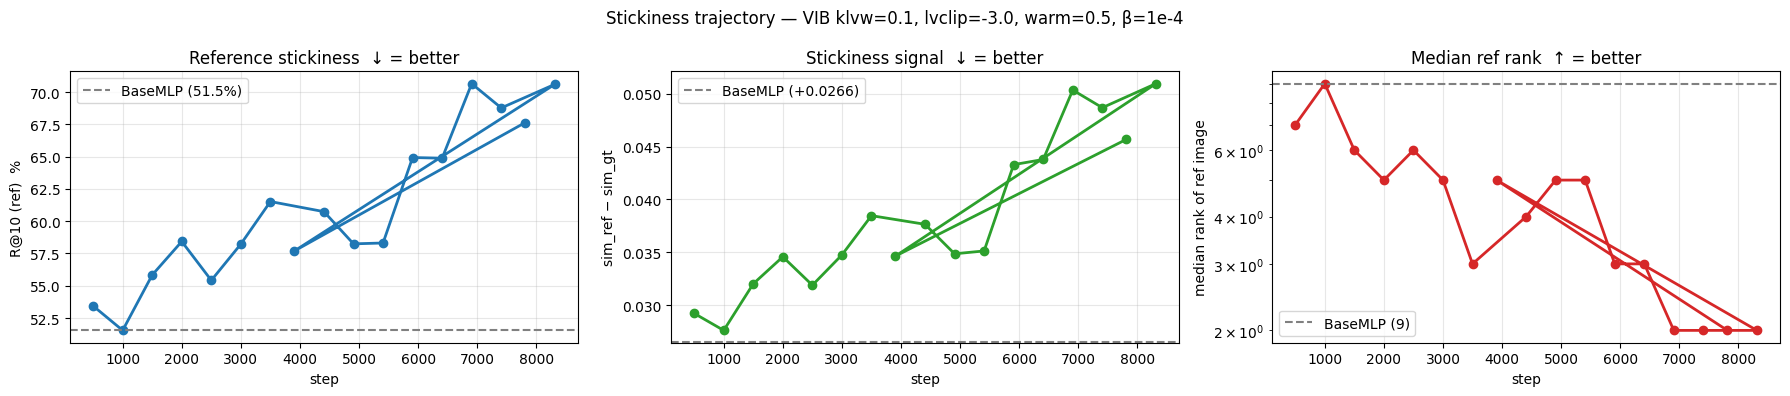

In [10]:
# Plot R10_ref, sim_Δ, median_ref over training steps.
# Compare against BaseMLP source baseline.

def step_from_label(lbl):
    if 'source' in lbl: return -1
    if lbl == 'epoch_00_end': return 3906
    if lbl == 'epoch_01_end': return 7812
    parts = lbl.split('_')
    # 'epoch_00_step_02500' or 'epoch_01_step_02500'
    try:
        epoch_num = int(parts[1])
        step_num = int(parts[-1])
        return epoch_num * 3906 + step_num
    except:
        return -1
    
df_stick['step_num'] = df_stick['label'].apply(step_from_label)
df_plot = df_stick[df_stick['step_num'] >= 0].copy()  # exclude source from x-axis
src = df_stick[df_stick['step_num'] == -1].iloc[0] if (df_stick['step_num'] == -1).any() else None

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# R10_ref over time
ax = axes[0]
ax.plot(df_plot['step_num'], df_plot['r10_ref']*100, 'o-', linewidth=2)
if src is not None:
    ax.axhline(y=src['r10_ref']*100, linestyle='--', color='gray',
               label=f'BaseMLP ({src["r10_ref"]*100:.1f}%)')
ax.set_xlabel('step')
ax.set_ylabel('R@10 (ref)  %')
ax.set_title('Reference stickiness  ↓ = better')
ax.legend()

# sim_Δ over time
ax = axes[1]
df_plot['sim_delta'] = df_plot['sim_ref'] - df_plot['sim_gt']
ax.plot(df_plot['step_num'], df_plot['sim_delta'], 'o-', linewidth=2, color='C2')
if src is not None:
    src_delta = src['sim_ref'] - src['sim_gt']
    ax.axhline(y=src_delta, linestyle='--', color='gray',
               label=f'BaseMLP ({src_delta:+.4f})')
ax.set_xlabel('step')
ax.set_ylabel('sim_ref − sim_gt')
ax.set_title('Stickiness signal  ↓ = better')
ax.legend()

# median_ref_rank over time
ax = axes[2]
ax.plot(df_plot['step_num'], df_plot['med_rank_ref'], 'o-', linewidth=2, color='C3')
if src is not None:
    ax.axhline(y=src['med_rank_ref'], linestyle='--', color='gray',
               label=f'BaseMLP ({src["med_rank_ref"]})')
ax.set_xlabel('step')
ax.set_ylabel('median rank of ref image')
ax.set_title('Median ref rank  ↑ = better')
ax.set_yscale('log')
ax.legend()

plt.suptitle(f'Stickiness trajectory — {RUN_LABEL}')
plt.tight_layout()
plt.show()

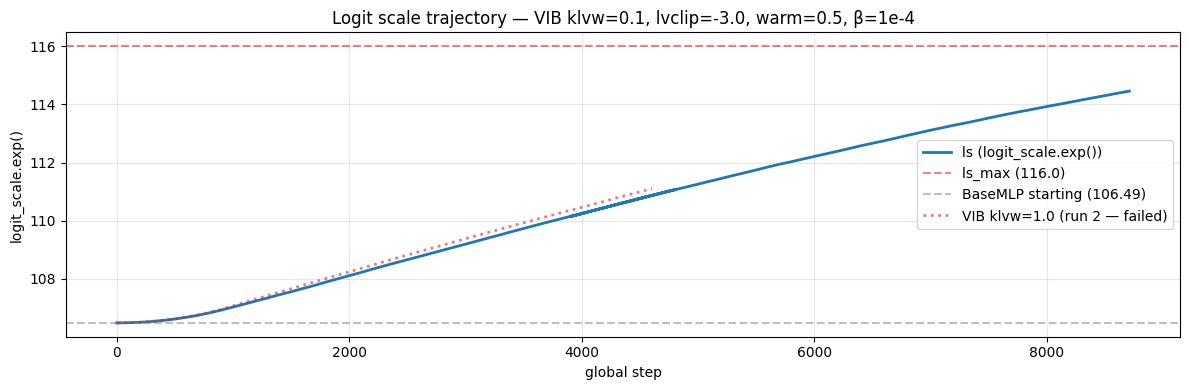


ls trajectory:
  start: 106.49
  end:   114.46
  delta: +7.97


In [11]:
# This tells us how aggressively the model is scaling cosine sims for the contrastive loss.

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df['global_step'], df['ls'], linewidth=2, label='ls (logit_scale.exp())')
ax.axhline(y=cfg_dict.get('ls_max', 100.0), linestyle='--', color='red', alpha=0.5, label=f'ls_max ({cfg_dict.get("ls_max")})')
ax.axhline(y=106.49, linestyle='--', color='gray', alpha=0.5, label='BaseMLP starting (106.49)')

if prev_tsv.exists():
    ax.plot(df_prev['global_step'], df_prev['ls'], linewidth=2, alpha=0.6,
            linestyle=':', color='C3', label=PREV_LABEL)

ax.set_xlabel('global step')
ax.set_ylabel('logit_scale.exp()')
ax.set_title(f'Logit scale trajectory — {RUN_LABEL}')
ax.legend()
plt.tight_layout()
plt.show()

print(f'\nls trajectory:')
print(f'  start: {df.iloc[0]["ls"]:.2f}')
print(f'  end:   {df.iloc[-1]["ls"]:.2f}')
print(f'  delta: {df.iloc[-1]["ls"] - df.iloc[0]["ls"]:+.2f}')

In [12]:
# === 12_summary_3way ===
# Final 3-way comparison: BaseMLP source vs run 2 (failed) vs run 3 (this run).

print('='*100)
print(f'  3-WAY COMPARISON  ({RUN_LABEL})')
print('='*100)

# Pull end-of-epoch stickiness for each run
def load_stickiness_overall(path_to_analysis_json):
    if not path_to_analysis_json.exists():
        return None
    a = json.load(open(path_to_analysis_json))
    return a.get('stickiness', {}).get('overall', {})

src_stick   = None  # BaseMLP doesn't have analysis.json (we'll print known values)
prev_stick  = load_stickiness_overall(PREV_RUN / 'epoch_00' / 'analysis.json')
cur_stick   = load_stickiness_overall(RUN_DIR / 'epoch_00' / 'analysis.json')

# Pull R@10 for each
src_r10  = SOURCE_R10_AVG
prev_r10 = json.load(open(PREV_RUN / 'epoch_00' / 'fashion_eval.json')).get('avg', {}).get('10', 0) * 100 if (PREV_RUN / 'epoch_00' / 'fashion_eval.json').exists() else 0
cur_r10  = json.load(open(RUN_DIR / 'epoch_00' / 'fashion_eval.json')).get('avg', {}).get('10', 0) * 100

# Pull μ_norm / σ from latest TSV row of each
cur_last = df.iloc[-1]
prev_last = df_prev.iloc[-1] if prev_tsv.exists() else None

print(f'\n{"Run":<40} {"R@10":>6} {"R10_ref":>8} {"med_ref":>8} {"sim_Δ":>7} {"μ_norm":>8} {"σ":>7}')
print('-' * 100)
print(f'{"BaseMLP slowLS source (ep01)":<40} {src_r10:>5.1f}% {"51.5%":>8} {"9":>8} {"+0.027":>7} {"7.71":>8} {"0":>7}')
if prev_stick:
    sim_d = prev_stick.get('avg_sim_ref',0) - prev_stick.get('avg_sim_gt',0)
    print(f'{PREV_LABEL:<40} {prev_r10:>5.1f}% {prev_stick.get("r10_ref",0)*100:>7.1f}% {prev_stick.get("median_rank_ref",0):>8} {sim_d:>+7.4f} {prev_last["mu_norm"]:>8.2f} {prev_last["std_mean"]:>7.4f}')
if cur_stick:
    sim_d = cur_stick.get('avg_sim_ref',0) - cur_stick.get('avg_sim_gt',0)
    print(f'{RUN_LABEL:<40} {cur_r10:>5.1f}% {cur_stick.get("r10_ref",0)*100:>7.1f}% {cur_stick.get("median_rank_ref",0):>8} {sim_d:>+7.4f} {cur_last["mu_norm"]:>8.2f} {cur_last["std_mean"]:>7.4f}')

print('\n→ Look at: lower R10_ref, lower sim_Δ, higher med_ref, lower μ_norm, lower σ all indicate healthier behavior.')

  3-WAY COMPARISON  (VIB klvw=0.1, lvclip=-3.0, warm=0.5, β=1e-4)

Run                                        R@10  R10_ref  med_ref   sim_Δ   μ_norm       σ
----------------------------------------------------------------------------------------------------
BaseMLP slowLS source (ep01)              25.8%    51.5%        9  +0.027     7.71       0
VIB klvw=1.0 (run 2 — failed)             22.8%    76.4% 1.333333 +0.0601    16.51  0.4796
VIB klvw=0.1, lvclip=-3.0, warm=0.5, β=1e-4  25.5%    57.7% 6.333333 +0.0346     7.65  0.1584

→ Look at: lower R10_ref, lower sim_Δ, higher med_ref, lower μ_norm, lower σ all indicate healthier behavior.
